# DRL Assignment 1: Proximal Policy Optimization
## Group 165 | Complete implementation and evidence notebook

| Contributor named in the supplied plan | BITS ID | Notebook coverage |
|---|---|---|
| Sachin Vaghela | 2025ag05794 | Motivation, actor-critic, rollout collection and PPO updates |
| Ayush | 2025ag05878 | Piecewise clipping derivatives and numerical verification |
| Deepank Dwivedi | 2025ag05945 | Experiment protocol, actual logs, evaluation and comparisons |
| Tanishka Vaswani | 2025ag05366 | Impact, reward optimization demonstration and limitations |


In [1]:
from pathlib import Path
import json, time, random, math
from dataclasses import dataclass, asdict, replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
import torch
from torch import nn
from torch.distributions import Categorical, Normal
from IPython.display import display, Markdown
torch.set_num_threads(1)
OUT = Path('ppo_outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})
VERSIONS = {m.__name__: m.__version__ for m in [np, pd, torch, gym]}
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / name, dpi=160, bbox_inches='tight')
    plt.show()


## 2. Motivation and mathematical foundation

A stochastic policy $\pi_\theta(a|s)$ chooses actions. A critic $V_\phi(s)$ estimates discounted
future reward. An advantage $\hat A_t$ estimates how much better an action is than the state's
baseline. Positive advantages encourage an action; negative advantages discourage it.
For a frozen behavior policy, compute the likelihood ratio in log space:

$$r_t(\theta)=\exp\big(\log\pi_\theta(a_t|s_t)-\log\pi_{\mathrm{old}}(a_t|s_t)\big).$$

Optimize the sample mean of $\min(r_t\hat A_t,\operatorname{clip}(r_t,1-\epsilon,1+\epsilon)\hat A_t)$.
The code minimizes its negative plus value squared error minus an entropy bonus. Old log
probabilities, advantages and return targets are constants during every epoch of a rollout update.
See [Schulman et al., 2017, Equations 7 and 9 and Algorithm 1](https://arxiv.org/pdf/1707.06347v2).

Our pedagogical implementation uses one actor and a shared two-layer tanh network. This is a
local experiment design, not the paper's continuous-control architecture or training budget.
The flow is: **collect T transitions -> estimate advantages -> freeze targets -> shuffle minibatches
for K epochs -> collect new experience**. Batch tensors have leading dimension T; each stored
log probability and value is a scalar per transition.


## 3. What clipping actually does

For one sample let $\ell(r,A)=\min(rA,\operatorname{clip}(r,1-\epsilon,1+\epsilon)A)$.
Working out the minimum gives:

$$\ell(r,A)=\begin{cases}A\min(r,1+\epsilon),& A>0,\\
A\max(r,1-\epsilon),& A<0,\\0,& A=0.\end{cases}$$

Away from a kink, $\partial\ell/\partial r$ is A for positive A below the upper threshold, and
A for negative A above the lower threshold; it is zero on the other respective branch.
In particular, **positive A still has gradient below 1-epsilon, and negative A still has gradient
above 1+epsilon**. There is no two-sided cutoff for every sample. At a kink the classical
derivative is undefined; automatic differentiation selects a subgradient.

By the chain rule, an active sample contributes $Ar\nabla_\theta\log\pi_\theta(a|s)$.
Other samples, shared parameters, value gradients and entropy gradients can still move a ratio
outside the interval. Clipping provides a pessimistic surrogate relative to the unclipped surrogate;
it is not a guaranteed lower bound on actual episodic return or a hard bound on KL divergence.


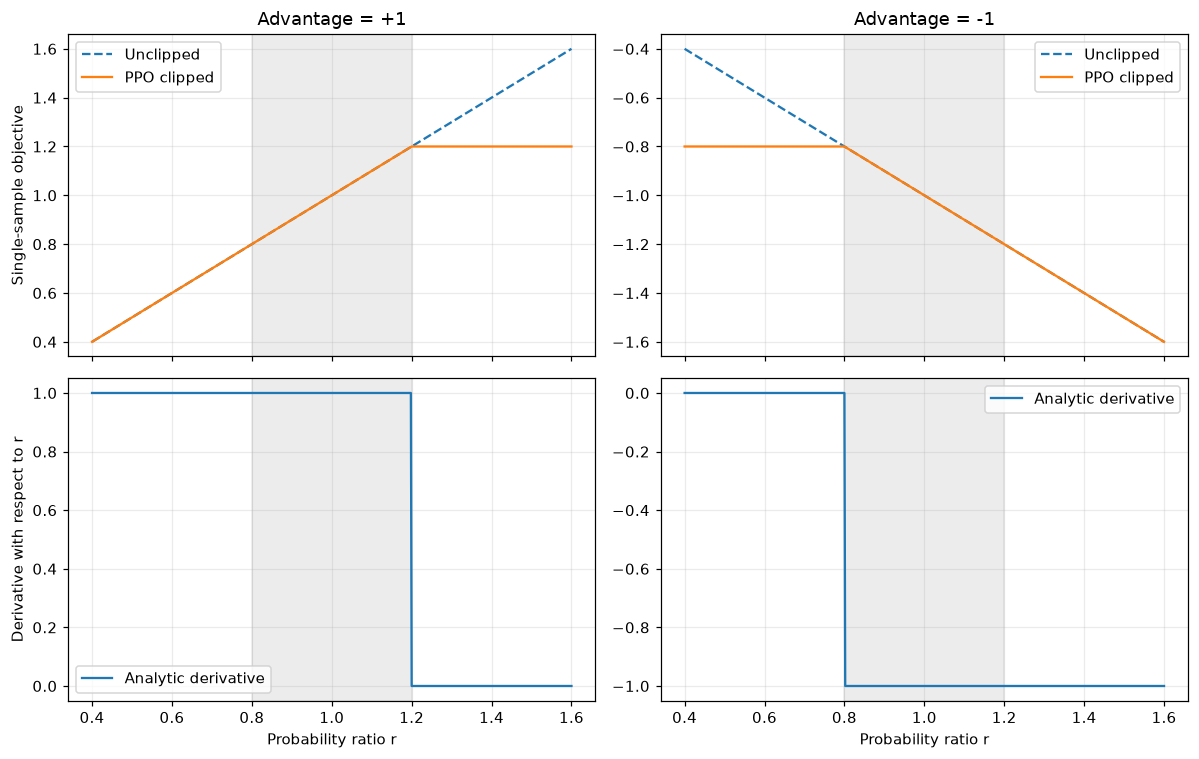

Piecewise derivatives agree with finite differences and autograd for both advantage signs.


In [3]:
def clipped_objective(ratio, advantage, epsilon=0.2):
    return np.minimum(ratio * advantage, np.clip(ratio, 1-epsilon, 1+epsilon) * advantage)
def clipped_derivative(ratio, advantage, epsilon=0.2):
    ratio = np.asarray(ratio, dtype=float)
    if advantage > 0:
        return np.where(ratio < 1+epsilon, advantage, 0.0)
    if advantage < 0:
        return np.where(ratio > 1-epsilon, advantage, 0.0)
    return np.zeros_like(ratio)

ratios = np.linspace(0.4, 1.6, 601)
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for col, advantage in enumerate([1.0, -1.0]):
    axes[0, col].plot(ratios, ratios*advantage, '--', label='Unclipped')
    axes[0, col].plot(ratios, clipped_objective(ratios, advantage), label='PPO clipped')
    axes[1, col].plot(ratios, clipped_derivative(ratios, advantage), label='Analytic derivative')
    axes[0, col].set_title(f'Advantage = {advantage:+.0f}')
    for row in range(2):
        axes[row, col].axvspan(0.8, 1.2, color='gray', alpha=0.15)
        axes[row, col].legend()
    axes[1, col].set_xlabel('Probability ratio r')
axes[0, 0].set_ylabel('Single-sample objective')
axes[1, 0].set_ylabel('Derivative with respect to r')
save_figure(fig, '01_clipping_and_gradients.png')

# Meaningful mathematical checks against central differences and PyTorch autograd.
probe = np.array([0.6, 0.9, 1.0, 1.1, 1.4])  # avoid nonsmooth thresholds
for advantage in [-1.0, 0.0, 1.0]:
    analytic = clipped_derivative(probe, advantage)
    h = 1e-6
    numerical = (clipped_objective(probe+h, advantage)-clipped_objective(probe-h, advantage))/(2*h)
    np.testing.assert_allclose(analytic, numerical, atol=1e-8)
    r = torch.tensor(probe, dtype=torch.float64, requires_grad=True)
    torch.minimum(r*advantage, r.clamp(0.8, 1.2)*advantage).sum().backward()
    np.testing.assert_allclose(r.grad.numpy(), analytic)
print('Piecewise derivatives agree with finite differences and autograd for both advantage signs.')


### TRPO and adaptive KL penalties

TRPO approximately optimizes a surrogate subject to a mean KL constraint using conjugate
gradient and a line search. Implementations use Fisher-vector products; forming a dense Fisher
matrix is not required. PPO-Clip instead uses ordinary first-order minibatch optimization.
Theoretical TRPO bounds have assumptions that practical approximations do not exactly enforce.
Neither a practical optimizer nor PPO should be presented as unconditionally improving every update.
See [TRPO, Schulman et al., 2015](https://arxiv.org/abs/1502.05477).

PPO-Penalty is an alternative that adapts a KL penalty coefficient. A larger observed KL increases
the coefficient for the next update; a smaller observed KL decreases it. The small helper below
demonstrates that adaptation rule, not a trained PPO-Penalty comparison.


In [4]:
def adapt_kl_coefficient(beta, observed_kl, target_kl=0.01):
    if observed_kl < target_kl / 1.5:
        return beta / 2
    if observed_kl > target_kl * 1.5:
        return beta * 2
    return beta
display(pd.DataFrame({'observed KL': [0.003, 0.01, 0.03],
                      'next beta (initial beta=1)': [adapt_kl_coefficient(1, d) for d in [0.003, 0.01, 0.03]]}))


,observed KL,next beta (initial beta=1)
0,0.003,0.5
1,0.010,1.0
2,0.030,2.0


## 4. Correct rollout targets: GAE and episode boundaries

Store reward, current value, next value, termination and truncation for **every** transition.
The recurrence implemented here is:

$$\delta_t=R_t+\gamma(1-\mathrm{terminated}_t)V(s_{t+1})-V(s_t),$$
$$\hat A_t=\delta_t+\gamma\lambda(1-\mathrm{episode\_end}_t)\hat A_{t+1},\quad
\hat R_t=\hat A_t+V(s_t).$$

A genuine terminal state has no future value. A time-limit truncation bootstraps from the final
observation's value but stops the recurrence from entering the reset episode. A rollout boundary
also bootstraps, while its future advantage is initialized to zero. Rewards are named R here to
avoid confusion with the policy ratio r. GAE weights distant TD residuals geometrically; it does
not weight a step 100 timesteps away equally to a step one timestep away.
See [GAE, Schulman et al.](https://arxiv.org/abs/1506.02438).


In [5]:
def compute_gae(rewards, values, next_values, terminated, episode_end, gamma=0.99, lam=0.95):
    rewards, values, next_values = [np.asarray(x, dtype=np.float32) for x in [rewards, values, next_values]]
    terminated, episode_end = [np.asarray(x, dtype=bool) for x in [terminated, episode_end]]
    assert all(x.shape == rewards.shape for x in [values, next_values, terminated, episode_end])
    advantages = np.zeros_like(rewards)
    carry = 0.0
    for t in reversed(range(len(rewards))):
        delta = rewards[t] + gamma*(not terminated[t])*next_values[t] - values[t]
        carry = delta + gamma*lam*(not episode_end[t])*carry
        advantages[t] = carry
    return advantages, advantages + values

# Every transition is retained, including the final one.
a, returns = compute_gae([1, 1], [0, 0], [0, 0], [False, True], [False, True], gamma=1, lam=1)
np.testing.assert_allclose(a, [2, 1])
# Truncation bootstraps from final state, but never carries reset-episode advantages.
a, _ = compute_gae([1, 100], [0, 0], [10, 0], [False, True], [True, True], gamma=0.9, lam=1)
np.testing.assert_allclose(a, [10, 100])
# A true terminal state ignores a spurious next value.
a, _ = compute_gae([1], [0], [999], [True], [True])
np.testing.assert_allclose(a, [1])
print('GAE terminal, truncation, length and bootstrap checks passed.')


GAE terminal, truncation, length and bootstrap checks passed.


## 5. Complete actor-critic and PPO implementation

For CartPole, two logits define a categorical distribution and the sampled action is an integer.
For Pendulum, the actor defines a diagonal Gaussian latent action, transformed with tanh and
scaled to the environment bounds. We store the latent action and evaluate the transformed
log density with its Jacobian correction; arbitrary Gaussian actions are never passed directly
to a bounded environment. Continuous entropy uses the analytic *latent* Gaussian entropy as
an optional proxy, explicitly not the transformed distribution's entropy; the Pendulum run
sets its entropy coefficient to zero.

The shared network returns logits/means of shape `(batch, action_dim)` and values of shape
`(batch,)`. Scalar log probabilities have shape `(batch,)`, so ratios do not accidentally broadcast
into a matrix. Gradient norm clipping below is distinct from PPO probability-ratio clipping.


In [6]:
@dataclass
class PPOConfig:
    total_steps: int = 30_720
    rollout_steps: int = 1024
    epochs: int = 4
    minibatch: int = 64
    learning_rate: float = 3e-4
    gamma: float = 0.99
    gae_lambda: float = 0.95
    epsilon: float = 0.2
    value_coef: float = 0.5
    entropy_coef: float = 0.01
    max_grad_norm: float = 0.5
    use_clipping: bool = True
    eval_every_updates: int = 5
    eval_episodes: int = 5

class ActorCritic(nn.Module):
    def __init__(self, observation_dim, action_space):
        super().__init__()
        self.discrete = isinstance(action_space, gym.spaces.Discrete)
        action_dim = action_space.n if self.discrete else int(np.prod(action_space.shape))
        self.body = nn.Sequential(nn.Linear(observation_dim, 64), nn.Tanh(), nn.Linear(64, 64), nn.Tanh())
        self.policy_head = nn.Linear(64, action_dim)
        self.value_head = nn.Linear(64, 1)
        for layer in self.modules():
            if isinstance(layer, nn.Linear):
                nn.init.orthogonal_(layer.weight, math.sqrt(2))
                nn.init.zeros_(layer.bias)
        nn.init.orthogonal_(self.policy_head.weight, 0.01)
        nn.init.orthogonal_(self.value_head.weight, 1.0)
        if not self.discrete:
            self.log_std = nn.Parameter(torch.zeros(action_dim))
            self.register_buffer('scale', torch.tensor((action_space.high-action_space.low)/2, dtype=torch.float32))
            self.register_buffer('bias', torch.tensor((action_space.high+action_space.low)/2, dtype=torch.float32))
            assert torch.all(self.scale > 0) and torch.all(torch.isfinite(self.scale))

    def forward(self, observations):
        features = self.body(observations)
        return self.policy_head(features), self.value_head(features).squeeze(-1)

    def distribution(self, observations):
        outputs, values = self(observations)
        if self.discrete:
            return Categorical(logits=outputs), values
        return Normal(outputs, self.log_std.clamp(-5, 2).exp().expand_as(outputs)), values

    def evaluate_actions(self, observations, stored_actions):
        dist, values = self.distribution(observations)
        if self.discrete:
            return dist.log_prob(stored_actions), dist.entropy(), values
        z = stored_actions
        # log(1-tanh(z)^2), expressed stably even for large |z|.
        log_jacobian = self.scale.log() + 2*(math.log(2)-z-nn.functional.softplus(-2*z))
        log_prob = (dist.log_prob(z)-log_jacobian).sum(-1)
        latent_entropy = dist.entropy().sum(-1)
        return log_prob, latent_entropy, values

    @torch.no_grad()
    def act(self, observation, deterministic=False):
        obs = torch.as_tensor(observation, dtype=torch.float32).reshape(1, -1)
        dist, _ = self.distribution(obs)
        if self.discrete:
            stored = dist.probs.argmax(-1) if deterministic else dist.sample()
            env_action = int(stored.item())
        else:
            stored = dist.mean if deterministic else dist.sample()
            env_action = (stored.tanh()*self.scale+self.bias).squeeze(0).numpy()
        log_prob, _, values = self.evaluate_actions(obs, stored)
        return env_action, stored.squeeze(0).numpy(), float(log_prob.item()), float(values.item())

class PPOAgent:
    def __init__(self, env, config):
        self.config = config
        self.model = ActorCritic(int(np.prod(env.observation_space.shape)), env.action_space)
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=config.learning_rate, eps=1e-5)

    @torch.no_grad()
    def value(self, observation):
        _, value = self.model(torch.as_tensor(observation, dtype=torch.float32).reshape(1, -1))
        return float(value.item())

    def update(self, data):
        c = self.config
        observations = torch.as_tensor(np.asarray(data['observations']), dtype=torch.float32)
        action_dtype = torch.long if self.model.discrete else torch.float32
        actions = torch.as_tensor(np.asarray(data['actions']), dtype=action_dtype)
        old_log_probs = torch.as_tensor(data['log_probs'], dtype=torch.float32).detach()
        advantage, returns = compute_gae(data['rewards'], data['values'], data['next_values'],
                                        data['terminated'], data['episode_end'], c.gamma, c.gae_lambda)
        advantages = torch.as_tensor(advantage)
        advantages = (advantages-advantages.mean()) / (advantages.std(unbiased=False)+1e-8)
        returns = torch.as_tensor(returns).detach()
        metrics = []
        for _ in range(c.epochs):
            for indices in torch.randperm(len(observations)).split(c.minibatch):
                new_lp, entropy, values = self.model.evaluate_actions(observations[indices], actions[indices])
                log_ratio = new_lp-old_log_probs[indices]
                ratio = log_ratio.exp()
                surrogate = ratio*advantages[indices]
                if c.use_clipping:
                    surrogate = torch.minimum(surrogate, ratio.clamp(1-c.epsilon, 1+c.epsilon)*advantages[indices])
                policy_loss = -surrogate.mean()
                value_loss = ((values-returns[indices])**2).mean()
                loss = policy_loss+c.value_coef*value_loss-c.entropy_coef*entropy.mean()
                if not torch.isfinite(loss):
                    raise FloatingPointError('Non-finite PPO loss')
                self.optimizer.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(self.model.parameters(), c.max_grad_norm)
                self.optimizer.step()
                with torch.no_grad():
                    # Nonnegative sample estimator of old-to-new KL; an estimate, not a constraint.
                    approx_kl = ((ratio-1)-log_ratio).mean()
                    clip_fraction = ((ratio-1).abs() > c.epsilon).float().mean()
                    metrics.append([policy_loss.item(), value_loss.item(), entropy.mean().item(),
                                    approx_kl.item(), clip_fraction.item()])
        return dict(zip(['policy_loss', 'value_loss', 'entropy', 'approx_kl', 'outside_clip_fraction'],
                        np.mean(metrics, axis=0).tolist()))


In [7]:
# Shape, density and finite-update checks exercise both action-space types.
for env_id in ['CartPole-v1', 'Pendulum-v1']:
    env = gym.make(env_id)
    obs, _ = env.reset(seed=123)
    agent = PPOAgent(env, PPOConfig())
    action, stored, lp, value = agent.model.act(obs)
    assert env.action_space.contains(action), (env_id, action)
    obs_t = torch.tensor(np.asarray([obs]), dtype=torch.float32)
    stored_t = torch.as_tensor(np.asarray([stored]), dtype=torch.long if agent.model.discrete else torch.float32)
    new_lp, entropy, values = agent.model.evaluate_actions(obs_t, stored_t)
    assert new_lp.shape == entropy.shape == values.shape == (1,)
    np.testing.assert_allclose(new_lp.detach().numpy(), [lp], atol=1e-5)
    np.testing.assert_allclose(torch.exp(new_lp-lp).detach().numpy(), [1.0], atol=1e-5)
    if not agent.model.discrete:
        from torch.distributions import Independent, TransformedDistribution, TanhTransform, AffineTransform
        dist, _ = agent.model.distribution(obs_t)
        reference = TransformedDistribution(Independent(dist, 1),
                    [TanhTransform(cache_size=1), AffineTransform(agent.model.bias, agent.model.scale, event_dim=1)])
        bounded = stored_t.tanh()*agent.model.scale+agent.model.bias
        np.testing.assert_allclose(new_lp.detach().numpy(), reference.log_prob(bounded).detach().numpy(), atol=1e-4)
    env.close()
print('Discrete and continuous action shapes, bounds, likelihood ratios and Jacobian checks passed.')


Discrete and continuous action shapes, bounds, likelihood ratios and Jacobian checks passed.


## 6. Actual experiment design

CartPole rewards one point per survived step, up to 500. We train four settings at equal
environment-step budgets using seeds 0, 1 and 2: clipping at 0.1, 0.2, 0.3, and an unclipped
multi-epoch surrogate. The last is an **unclipped-surrogate ablation**, not A2C, TRPO or standard
single-update REINFORCE. All other settings stay fixed, including gradient-norm clipping.

Every five rollout updates, evaluate in a separate environment using five fixed held-out reset
seeds and deterministic actions. Evaluation never enters the training buffer. Evaluation is not
a guarantee of success for the stochastic policy. We also measure a random-action baseline.
The final policy and configuration are saved for each run; each log records the seed and setting.
Use more training seeds and a larger step budget for a serious benchmark study.

Shaded bands below represent **one standard deviation across training seeds**, not a 95% confidence
interval. We do not claim statistical significance from three seeds. A small CartPole ablation
need not rank epsilon settings like MuJoCo or show catastrophic failure without clipping.


In [8]:
def evaluate(env_id, model=None, episodes=5, base_seed=10_000):
    env = gym.make(env_id)
    scores = []
    try:
        for episode in range(episodes):
            obs, _ = env.reset(seed=base_seed+episode)
            env.action_space.seed(base_seed+episode)
            total = 0.0
            done = False
            while not done:
                action = env.action_space.sample() if model is None else model.act(obs, deterministic=True)[0]
                obs, reward, terminated, truncated, _ = env.step(action)
                total += reward
                done = terminated or truncated
            scores.append(total)
    finally:
        env.close()
    return np.asarray(scores, dtype=float)

def train(env_id, config, seed, label):
    seed_everything(seed)
    env = gym.make(env_id)
    obs, _ = env.reset(seed=seed)
    env.action_space.seed(seed)
    agent = PPOAgent(env, config)
    updates, evaluations, episodes = [], [], []
    episode_reward, episode_length, steps, update_index = 0.0, 0, 0, 0
    started = time.perf_counter()
    def record_evaluation():
        scores = evaluate(env_id, agent.model, config.eval_episodes)
        evaluations.append(dict(setting=label, seed=seed, steps=steps, eval_mean=float(scores.mean()),
                                eval_std=float(scores.std(ddof=1)), scores=scores.tolist()))
    record_evaluation()
    try:
        while steps < config.total_steps:
            data = {key: [] for key in ['observations', 'actions', 'log_probs', 'rewards', 'values',
                                        'next_values', 'terminated', 'episode_end']}
            for _ in range(min(config.rollout_steps, config.total_steps-steps)):
                action, stored, lp, value = agent.model.act(obs)
                next_obs, reward, terminated, truncated, _ = env.step(action)
                done = terminated or truncated
                next_value = 0.0 if terminated else agent.value(next_obs)
                for key, item in zip(data, [obs.copy(), stored, lp, reward, value, next_value, terminated, done]):
                    data[key].append(item)
                episode_reward += reward
                episode_length += 1
                steps += 1
                if done:
                    episodes.append(dict(setting=label, seed=seed, steps=steps, reward=episode_reward,
                                         length=episode_length, terminated=bool(terminated), truncated=bool(truncated)))
                    obs, _ = env.reset()
                    episode_reward, episode_length = 0.0, 0
                else:
                    obs = next_obs
            update_index += 1
            metrics = agent.update(data)
            updates.append(dict(setting=label, seed=seed, steps=steps, **metrics))
            if update_index % config.eval_every_updates == 0 or steps == config.total_steps:
                record_evaluation()
    finally:
        env.close()
    elapsed = time.perf_counter()-started
    run_dir = OUT / env_id / label / f'seed_{seed}'
    run_dir.mkdir(parents=True, exist_ok=True)
    pd.DataFrame(updates).to_csv(run_dir/'updates.csv', index=False)
    pd.DataFrame(episodes).to_csv(run_dir/'episodes.csv', index=False)
    (run_dir/'evaluations.json').write_text(json.dumps(evaluations, indent=2), encoding='utf-8')
    (run_dir/'config.json').write_text(json.dumps(dict(env_id=env_id, seed=seed, setting=label,
                      config=asdict(config), elapsed_seconds=elapsed, versions=VERSIONS), indent=2), encoding='utf-8')
    torch.save(agent.model.state_dict(), run_dir/'policy.pt')
    print(f'{env_id} | {label} | seed {seed} | steps {steps:,} | final eval {evaluations[-1]["eval_mean"]:.1f} | {elapsed:.1f}s')
    return dict(agent=agent, updates=updates, evaluations=evaluations, episodes=episodes, elapsed=elapsed)

BASE_CONFIG = PPOConfig()
SEEDS = [0, 1, 2]
SETTINGS = {'clip_0.1': replace(BASE_CONFIG, epsilon=0.1),
            'clip_0.2': BASE_CONFIG,
            'clip_0.3': replace(BASE_CONFIG, epsilon=0.3),
            'unclipped': replace(BASE_CONFIG, use_clipping=False)}
print('Actual study configuration:', asdict(BASE_CONFIG), '| seeds:', SEEDS)
random_baseline = evaluate('CartPole-v1', episodes=20)
print(f'Random baseline: {random_baseline.mean():.1f} +/- {random_baseline.std(ddof=1):.1f} (episode SD, 20 episodes)')
runs = {(label, seed): train('CartPole-v1', config, seed, label)
        for label, config in SETTINGS.items() for seed in SEEDS}


Actual study configuration: {'total_steps': 30720, 'rollout_steps': 1024, 'epochs': 4, 'minibatch': 64, 'learning_rate': 0.0003, 'gamma': 0.99, 'gae_lambda': 0.95, 'epsilon': 0.2, 'value_coef': 0.5, 'entropy_coef': 0.01, 'max_grad_norm': 0.5, 'use_clipping': True, 'eval_every_updates': 5, 'eval_episodes': 5} | seeds: [0, 1, 2]
Random baseline: 24.1 +/- 10.8 (episode SD, 20 episodes)
CartPole-v1 | clip_0.1 | seed 0 | steps 30,720 | final eval 151.2 | 25.3s
CartPole-v1 | clip_0.1 | seed 1 | steps 30,720 | final eval 126.4 | 19.4s
CartPole-v1 | clip_0.1 | seed 2 | steps 30,720 | final eval 201.0 | 25.6s
CartPole-v1 | clip_0.2 | seed 0 | steps 30,720 | final eval 113.4 | 20.8s
CartPole-v1 | clip_0.2 | seed 1 | steps 30,720 | final eval 457.2 | 19.8s
CartPole-v1 | clip_0.2 | seed 2 | steps 30,720 | final eval 278.2 | 19.9s
CartPole-v1 | clip_0.3 | seed 0 | steps 30,720 | final eval 133.2 | 19.7s
CartPole-v1 | clip_0.3 | seed 1 | steps 30,720 | final eval 149.8 | 22.1s
CartPole-v1 | clip_0.3

,setting,mean_final_return,SD_across_training_seeds,min,max,count
0,clip_0.1,159.53,37.99,126.4,201.0,3
1,clip_0.2,282.93,171.95,113.4,457.2,3
2,clip_0.3,144.53,9.82,133.2,150.6,3
3,unclipped,312.53,170.41,116.6,426.2,3


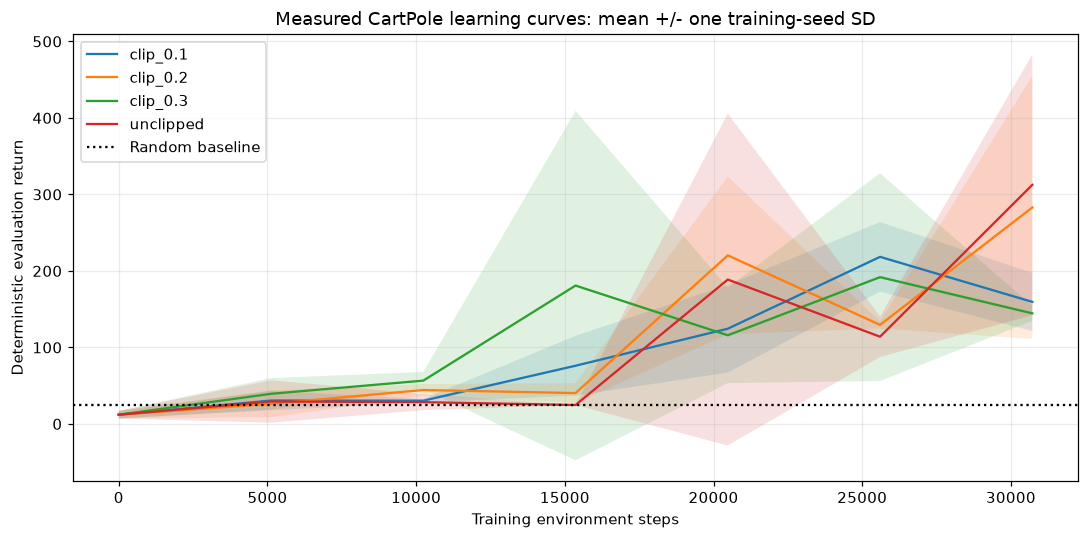

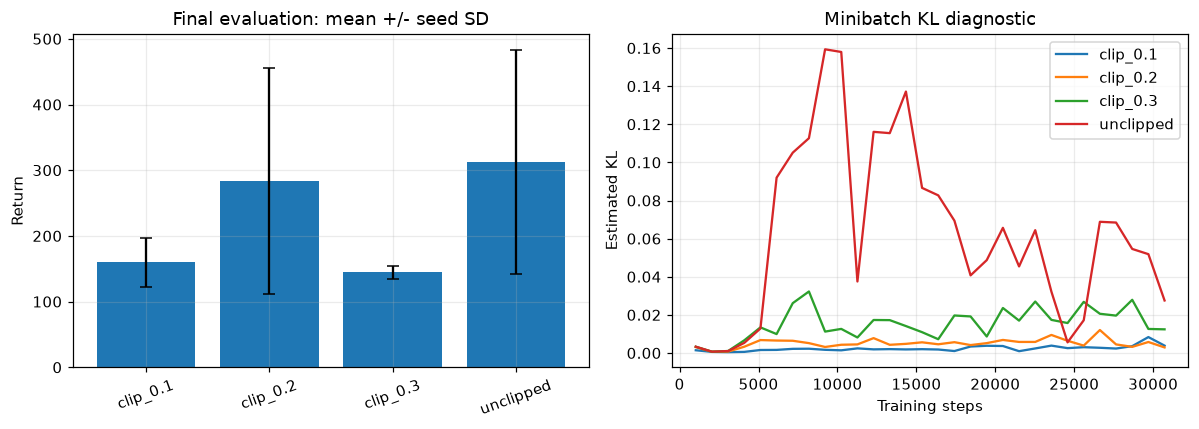

**Measured local results:** Clip 0.2 final mean = 282.9;
unclipped final mean = 312.5; random baseline mean = 24.1.
The highest sample mean belongs to `unclipped`. These small-sample observations do not
establish a statistically significant ranking or a universal epsilon choice.
The observed clip-minus-unclipped difference is -29.6 return points.

In [9]:
evaluation_df = pd.DataFrame([row for run in runs.values() for row in run['evaluations']])
update_df = pd.DataFrame([row for run in runs.values() for row in run['updates']])
final_df = evaluation_df.sort_values('steps').groupby(['setting', 'seed'], as_index=False).tail(1)
summary = final_df.groupby('setting')['eval_mean'].agg(['mean', 'std', 'min', 'max', 'count']).reset_index()
summary = summary.rename(columns={'mean': 'mean_final_return', 'std': 'SD_across_training_seeds'})
display(summary.round(2))
summary.to_csv(OUT/'cartpole_summary.csv', index=False)
evaluation_df.to_json(OUT/'cartpole_evaluations.json', orient='records', indent=2)

fig, ax = plt.subplots(figsize=(10, 5))
for label in SETTINGS:
    stats = evaluation_df[evaluation_df.setting == label].groupby('steps').eval_mean.agg(['mean', 'std'])
    x, y, sd = stats.index.to_numpy(), stats['mean'].to_numpy(), stats['std'].fillna(0).to_numpy()
    ax.plot(x, y, label=label)
    ax.fill_between(x, y-sd, y+sd, alpha=0.14)
ax.axhline(random_baseline.mean(), color='black', linestyle=':', label='Random baseline')
ax.set(xlabel='Training environment steps', ylabel='Deterministic evaluation return',
       title='Measured CartPole learning curves: mean +/- one training-seed SD')
ax.legend()
save_figure(fig, '02_cartpole_learning_curves.png')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(summary.setting, summary.mean_final_return,
            yerr=summary.SD_across_training_seeds, capsize=4)
axes[0].set(title='Final evaluation: mean +/- seed SD', ylabel='Return')
axes[0].tick_params(axis='x', rotation=20)
for label in SETTINGS:
    stats = update_df[update_df.setting == label].groupby('steps').approx_kl.mean()
    axes[1].plot(stats.index, stats.values, label=label)
axes[1].set(title='Minibatch KL diagnostic', xlabel='Training steps', ylabel='Estimated KL')
axes[1].legend()
save_figure(fig, '03_final_returns_and_kl.png')

# Conclusions depend on actual measurements, including inconclusive ablations.
clip_mean = float(summary.loc[summary.setting == 'clip_0.2', 'mean_final_return'].iloc[0])
unclip_mean = float(summary.loc[summary.setting == 'unclipped', 'mean_final_return'].iloc[0])
best_setting = summary.loc[summary.mean_final_return.idxmax(), 'setting']
display(Markdown(f'''**Measured local results:** Clip 0.2 final mean = {clip_mean:.1f};
unclipped final mean = {unclip_mean:.1f}; random baseline mean = {random_baseline.mean():.1f}.
The highest sample mean belongs to `{best_setting}`. These small-sample observations do not
establish a statistically significant ranking or a universal epsilon choice.
The observed clip-minus-unclipped difference is {clip_mean-unclip_mean:+.1f} return points.'''))


### Continuous-action demonstration

Pendulum tests the bounded continuous policy on real environment transitions. Its return is
negative; a less negative return is better. The short run below is an execution and learning
demonstration with one seed, not evidence of convergence, comparative superiority or MuJoCo
reproduction. CartPole is the controlled multi-seed study; Pendulum extends action-space coverage.


Pendulum-v1 | clip_0.2_continuous | seed 0 | steps 8,192 | final eval -1034.5 | 6.3s


,steps,eval_mean,eval_std
0,0,-924.086195,274.026522
1,5120,-1066.435478,48.115331
2,8192,-1034.509232,47.224220


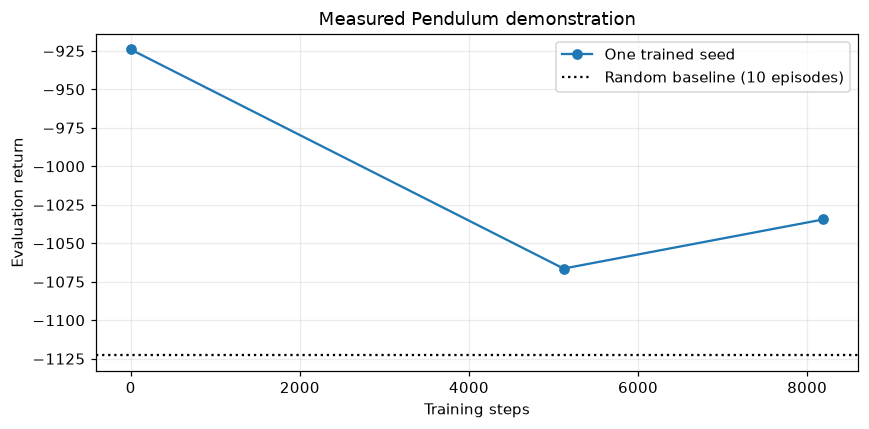

In [10]:
pendulum_config = replace(BASE_CONFIG, total_steps=8192, entropy_coef=0.0, eval_episodes=3)
pendulum_random = evaluate('Pendulum-v1', episodes=10)
pendulum_run = train('Pendulum-v1', pendulum_config, seed=0, label='clip_0.2_continuous')
pendulum_evaluations = pd.DataFrame(pendulum_run['evaluations'])
display(pendulum_evaluations[['steps', 'eval_mean', 'eval_std']])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(pendulum_evaluations.steps, pendulum_evaluations.eval_mean, marker='o', label='One trained seed')
ax.axhline(pendulum_random.mean(), linestyle=':', color='black', label='Random baseline (10 episodes)')
ax.set(xlabel='Training steps', ylabel='Evaluation return', title='Measured Pendulum demonstration')
ax.legend()
save_figure(fig, '04_pendulum_demo.png')


## 7. Verified published evidence, separate from local experiments

The following values are transcribed from Tables 1 and 2 of the
[public PPO paper, v2](https://arxiv.org/pdf/1707.06347v2), not measured by this notebook.
Table 1 aggregates seven environments x three seeds, normalized with random = 0 and the best
result = 1, not expert = 1. The no-clipping entry is an aggregate, not a HalfCheetah score.
Table 2 counts wins across 49 Atari games; final PPO wins are 19. The paper's Atari clipping
parameter is annealed from 0.1, contradicting the template's universal 0.2 claim.
No invented per-task scores, raw seed observations, confidence intervals or significance tests
are attached to these published aggregate values.


,setting,published_normalized_score
0,No clipping or penalty,-0.39
1,Clip 0.1,0.76
2,Clip 0.2,0.82
3,Clip 0.3,0.70
4,Adaptive KL 0.003,0.68
5,Adaptive KL 0.01,0.74
6,Adaptive KL 0.03,0.71
7,Fixed KL beta 0.3,0.62
8,Fixed KL beta 1,0.71
9,Fixed KL beta 3,0.72


,scoring_metric,A2C,ACER,PPO,Tie
0,Whole training,1,18,30,0
1,Last 100 episodes,1,28,19,1


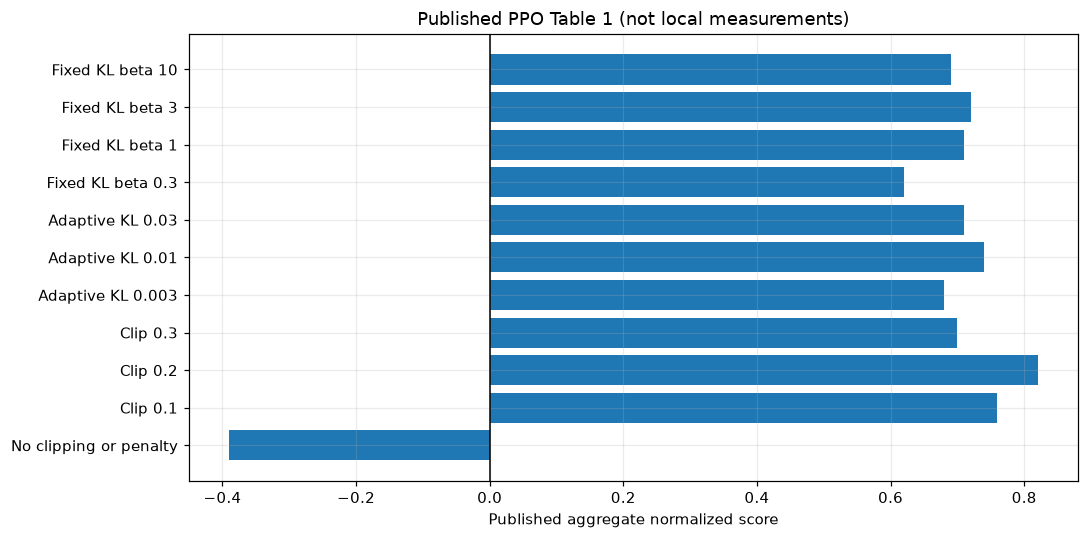

In [11]:
paper_objectives = pd.DataFrame({
    'setting': ['No clipping or penalty', 'Clip 0.1', 'Clip 0.2', 'Clip 0.3',
                'Adaptive KL 0.003', 'Adaptive KL 0.01', 'Adaptive KL 0.03',
                'Fixed KL beta 0.3', 'Fixed KL beta 1', 'Fixed KL beta 3', 'Fixed KL beta 10'],
    'published_normalized_score': [-0.39, 0.76, 0.82, 0.70, 0.68, 0.74, 0.71, 0.62, 0.71, 0.72, 0.69]})
paper_atari = pd.DataFrame({'scoring_metric': ['Whole training', 'Last 100 episodes'],
                          'A2C': [1, 1], 'ACER': [18, 28], 'PPO': [30, 19], 'Tie': [0, 1]})
assert (paper_atari[['A2C', 'ACER', 'PPO', 'Tie']].sum(axis=1) == 49).all()
display(paper_objectives)
display(paper_atari)
paper_objectives.to_csv(OUT/'published_table_1.csv', index=False)
paper_atari.to_csv(OUT/'published_table_2.csv', index=False)
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(paper_objectives.setting, paper_objectives.published_normalized_score)
ax.axvline(0, color='black', linewidth=1)
ax.set(xlabel='Published aggregate normalized score', title='Published PPO Table 1 (not local measurements)')
save_figure(fig, '05_published_objective_comparison.png')


## 8. Practical impact and a reward optimization example

PPO supplies a policy optimizer; the quality of the reward remains a separate design problem.
As a documented historical application, [Ouyang et al., 2022, InstructGPT](https://arxiv.org/abs/2203.02155)
uses supervised demonstrations, a learned preference reward model and PPO fine-tuning. That does
not establish the optimizer used in every current language model or validate the template's
adoption percentages and company-specific claims.

The toy example below has three possible responses and a fixed hand-written reward. It performs
PPO-style optimization on categorical responses using a frozen old distribution per batch and
an exact KL penalty to a reference distribution. This reference KL penalty is conceptually
different from clipping the ratio to the *previous* policy. It is not a learned reward model,
human feedback collection, language model training or a reproduction of InstructGPT.


,response,initial_probability,final_probability,fixed_reward
0,Helpful answer,0.333333,0.988349,1.0
1,Vague answer,0.333333,0.006064,0.2
2,Unsafe answer,0.333333,0.005587,-1.0


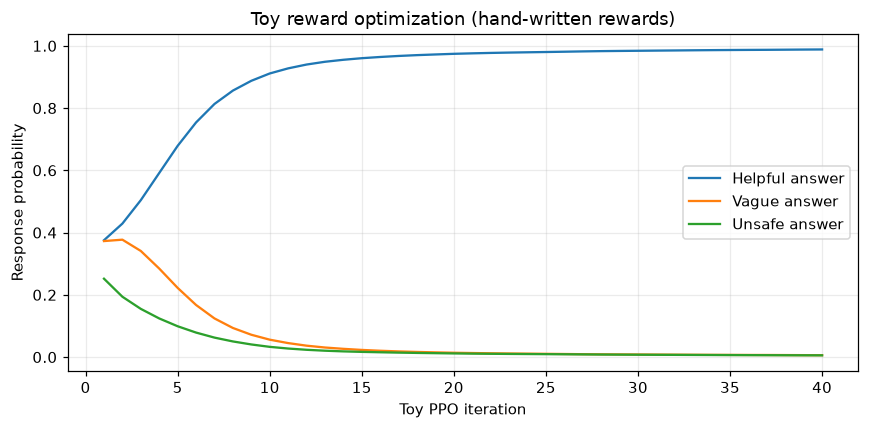

In [12]:
seed_everything(7)
response_names = ['Helpful answer', 'Vague answer', 'Unsafe answer']
toy_rewards = torch.tensor([1.0, 0.2, -1.0])
toy_logits = nn.Parameter(torch.zeros(3))
toy_optimizer = torch.optim.Adam([toy_logits], lr=0.05)
reference_probs = torch.full((3,), 1/3)
toy_history = []
for iteration in range(40):
    old_dist = Categorical(logits=toy_logits.detach().clone())
    actions = old_dist.sample((256,))
    old_lp = old_dist.log_prob(actions).detach()
    advantages = (toy_rewards[actions]-(old_dist.probs*toy_rewards).sum()).detach()
    for _ in range(4):
        new_dist = Categorical(logits=toy_logits)
        ratios = (new_dist.log_prob(actions)-old_lp).exp()
        objective = torch.minimum(ratios*advantages, ratios.clamp(0.8, 1.2)*advantages).mean()
        kl_reference = (new_dist.probs*(new_dist.probs.log()-reference_probs.log())).sum()
        loss = -objective+0.1*kl_reference
        toy_optimizer.zero_grad()
        loss.backward()
        toy_optimizer.step()
    with torch.no_grad():
        probs = torch.softmax(toy_logits, dim=0).numpy()
        toy_history.append(probs)
toy_history = np.asarray(toy_history)
display(pd.DataFrame({'response': response_names, 'initial_probability': [1/3]*3,
                      'final_probability': toy_history[-1], 'fixed_reward': toy_rewards.numpy()}))
fig, ax = plt.subplots(figsize=(8, 4))
for idx, name in enumerate(response_names):
    ax.plot(np.arange(1, 41), toy_history[:, idx], label=name)
ax.set(xlabel='Toy PPO iteration', ylabel='Response probability', title='Toy reward optimization (hand-written rewards)')
ax.legend()
save_figure(fig, '06_toy_reward_optimization.png')


## 9. Limitations and future directions

* **Fresh data cost:** Multi-epoch batch reuse helps, but subsequent iterations require new
  experience. This implementation is not an offline RL learner.
* **No hard safety boundary:** Clipping cannot enforce safe actions, monotonic return improvement
  or a specified KL limit. Monitor returns, KL estimates and losses; consider explicit constraints
  when a task actually requires them.
* **Hyperparameters:** Learning rate, rollout length, epoch count, entropy weight and epsilon
  interact. A best sample mean in this small study is not a universal optimum.
* **Credit assignment:** Gamma and lambda control how distant TD residuals contribute. Sparse
  rewards and delayed consequences can still make estimation difficult.
* **Reward misspecification:** Maximizing a poorly designed reward can favor unintended behavior.
  The toy reward example assumes its hand-written rankings are appropriate.
* **Experimental scope:** Three seeds, a short training budget and simple simulators limit external
  validity. Evaluation SD across episodes differs from SD across independently trained policies.
* **Continuous policy:** Squashed Gaussian actions respect bounds but differ from the original
  continuous benchmark policy. Observation/reward normalization is omitted in this teaching code.

Potential extensions proposed for this project are more seeds, held-out evaluation reset seeds,
longer training, adaptive KL monitoring, reward auditing, and carefully scoped continuous-control
benchmarks. These are our suggested next experiments, not purported sections of the 2017 paper.
